# Stage 5: Model Evaluation and Comparison

## Objective
Evaluate the five trained classification models on the same held-out test dataset and compare their performance using the six metrics required by the assignment.

### Models
1. Logistic Regression
2. Decision Tree
3. K-Nearest Neighbors (KNN)
4. Gaussian Naive Bayes
5. Support Vector Machine (SVM)

### Required evaluation metrics
- Accuracy
- AUC Score (ROC-AUC)
- Precision
- Recall
- F1 Score
- Matthews Correlation Coefficient (MCC)

**Input:** `data/processed/test_processed.csv` and fitted models in `models/`  
**Output:** Metrics comparison CSV, classification reports, confusion matrices, and ROC curve.

> Run Stages 3 and 4 successfully before running this notebook. The test data must not be used to fit models or preprocessing transformations.

## 5.1 Import libraries and load test data

Load the processed test dataset created in Stage 3. The `target` column contains encoded labels: `0 = no` and `1 = yes`.

In [1]:
import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay,
    roc_curve
)

sns.set_theme(style="whitegrid")

test_path = "../data/processed/test_processed.csv"
model_dir = "../models"
results_dir = "../results"
os.makedirs(results_dir, exist_ok=True)

test_data = pd.read_csv(test_path)

print("Test dataset shape:", test_data.shape)
display(test_data.head())

Test dataset shape: (905, 51)


,num__age,num__balance,num__day,num__campaign,num__pdays,num__previous,cat__job_admin.,cat__job_blue-collar,cat__job_entrepreneur,cat__job_housemaid,...,cat__month_mar,cat__month_may,cat__month_nov,cat__month_oct,cat__month_sep,cat__poutcome_failure,cat__poutcome_other,cat__poutcome_success,cat__poutcome_unknown,target
0,1.716087,0.114933,1.091788,0.383107,3.172855,0.877541,0.0,0.0,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1
1,-0.099774,-0.460684,0.482468,6.107549,-0.411541,-0.329453,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0
2,0.282513,-0.343639,-0.979900,0.065082,2.623713,0.274044,0.0,0.0,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0
3,-1.151062,-0.535749,-1.467356,-0.570967,-0.411541,-0.329453,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0
4,1.142658,-0.447521,1.701108,-0.570967,-0.411541,-0.329453,0.0,0.0,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0


## 5.2 Separate test features and target

Separate the transformed input features (`X_test`) from the encoded target (`y_test`). Keep the test observations in their original order so that every model is evaluated on exactly the same records.

In [2]:
X_test = test_data.drop(columns=["target"])
y_test = test_data["target"].astype(int)

# Stage 4 trained the estimators with a NumPy array, so use the same representation.
X_test_model = X_test.to_numpy()

print("X_test shape:", X_test_model.shape)
print("y_test shape:", y_test.shape)
print("\nTest target distribution:")
display(y_test.value_counts().sort_index().rename(index={0: "no (0)", 1: "yes (1)"}).to_frame("Count"))

X_test shape: (905, 50)
y_test shape: (905,)

Test target distribution:


,Count
target,
no (0),801
yes (1),104


## 5.3 Load the five fitted models

Load the model artifacts saved in Stage 4. Do not refit them in this notebook.

In [3]:
model_files = {
    "Logistic Regression": "logistic_regression.joblib",
    "Decision Tree": "decision_tree.joblib",
    "K-Nearest Neighbors": "knn.joblib",
    "Gaussian Naive Bayes": "gaussian_nb.joblib",
    "Support Vector Machine": "svm.joblib"
}

models = {}

for model_name, filename in model_files.items():
    model_path = os.path.join(model_dir, filename)
    models[model_name] = joblib.load(model_path)
    print(f"Loaded: {model_name} from {model_path}")

print("\nTotal models loaded:", len(models))

Loaded: Logistic Regression from ../models\logistic_regression.joblib
Loaded: Decision Tree from ../models\decision_tree.joblib
Loaded: K-Nearest Neighbors from ../models\knn.joblib
Loaded: Gaussian Naive Bayes from ../models\gaussian_nb.joblib
Loaded: Support Vector Machine from ../models\svm.joblib

Total models loaded: 5


## 5.4 Generate predictions and probability scores

For each model:
- `predict()` produces the predicted class labels used for Accuracy, Precision, Recall, F1, MCC, and the confusion matrix.
- `predict_proba()` produces the estimated probability of class `1` (`yes`), used to calculate ROC-AUC.

The SVM was configured with `probability=True` in Stage 4 for this purpose.

In [4]:
predictions = {}
probabilities = {}

for model_name, model in models.items():
    predictions[model_name] = model.predict(X_test_model)

    if not hasattr(model, "predict_proba"):
        raise AttributeError(
            f"{model_name} does not support predict_proba(). "
            "Check the model configuration used in Stage 4."
        )

    # The positive class is encoded as 1 (yes).
    positive_class_index = list(model.classes_).index(1)
    probabilities[model_name] = model.predict_proba(X_test_model)[:, positive_class_index]

    print(f"{model_name}: predictions generated")

Logistic Regression: predictions generated
Decision Tree: predictions generated
K-Nearest Neighbors: predictions generated
Gaussian Naive Bayes: predictions generated
Support Vector Machine: predictions generated


## 5.5 Calculate the six evaluation metrics

All metrics are calculated using the same held-out test labels.

For Precision, Recall, and F1, use `pos_label=1`, meaning the positive class is customers who subscribed (`yes`). `zero_division=0` avoids undefined-metric warnings if a model predicts no positive cases.

ROC-AUC is calculated from probability scores rather than hard class predictions.

In [5]:
metrics_rows = []

for model_name in models:
    y_pred = predictions[model_name]
    y_score = probabilities[model_name]

    metrics_rows.append({
        "ML Model Name": model_name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "AUC": roc_auc_score(y_test, y_score),
        "Precision": precision_score(y_test, y_pred, pos_label=1, zero_division=0),
        "Recall": recall_score(y_test, y_pred, pos_label=1, zero_division=0),
        "F1": f1_score(y_test, y_pred, pos_label=1, zero_division=0),
        "MCC": matthews_corrcoef(y_test, y_pred)
    })

metrics_df = pd.DataFrame(metrics_rows).set_index("ML Model Name")
display(metrics_df.round(4))

,Accuracy,AUC,Precision,Recall,F1,MCC
ML Model Name,,,,,,
Logistic Regression,0.8873,0.7376,0.5333,0.1538,0.2388,0.2429
Decision Tree,0.8088,0.5657,0.2149,0.2500,0.2311,0.1231
K-Nearest Neighbors,0.8762,0.6112,0.2778,0.0481,0.0820,0.0727
Gaussian Naive Bayes,0.8099,0.7166,0.2763,0.4038,0.3281,0.2274
Support Vector Machine,0.8884,0.6909,0.5600,0.1346,0.2171,0.2352


## 5.6 Compare model performance

The comparison table below presents all six required metrics. Higher values are generally better for each metric, but the most appropriate model depends on the problem objective and the trade-off between false positives and false negatives.

For this dataset, the positive class (`yes`) is the minority class. Recall indicates how many actual subscribers are identified, while Precision indicates how many customers predicted as subscribers actually subscribed.

In [6]:
metrics_comparison = metrics_df.copy().round(4)
metrics_comparison.to_csv(
    os.path.join(results_dir, "model_metrics_comparison.csv")
)
print("Saved:", os.path.join(results_dir, "model_metrics_comparison.csv"))
display(metrics_comparison)

Saved: ../results\model_metrics_comparison.csv


,Accuracy,AUC,Precision,Recall,F1,MCC
ML Model Name,,,,,,
Logistic Regression,0.8873,0.7376,0.5333,0.1538,0.2388,0.2429
Decision Tree,0.8088,0.5657,0.2149,0.2500,0.2311,0.1231
K-Nearest Neighbors,0.8762,0.6112,0.2778,0.0481,0.0820,0.0727
Gaussian Naive Bayes,0.8099,0.7166,0.2763,0.4038,0.3281,0.2274
Support Vector Machine,0.8884,0.6909,0.5600,0.1346,0.2171,0.2352


## 5.7 Confusion matrices

A confusion matrix compares actual labels with predicted labels.

For binary classification with `yes = 1` as the positive class:

| | Predicted No (0) | Predicted Yes (1) |
|---|---:|---:|
| Actual No (0) | True Negative (TN) | False Positive (FP) |
| Actual Yes (1) | False Negative (FN) | True Positive (TP) |

The confusion matrix helps explain the Precision and Recall values, especially for the minority positive class.

In [ ]:
for model_name in models:
    cm = confusion_matrix(y_test, predictions[model_name], labels=[0, 1])

    plt.figure(figsize=(5, 4))
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Predicted No", "Predicted Yes"],
        yticklabels=["Actual No", "Actual Yes"]
    )
    plt.title(f"Confusion Matrix: {model_name}")
    plt.xlabel("Predicted Label")
    plt.ylabel("Actual Label")
    plt.tight_layout()
    plt.show()

    cm_df = pd.DataFrame(
        cm,
        index=["Actual No", "Actual Yes"],
        columns=["Predicted No", "Predicted Yes"]
    )
    safe_name = model_name.lower().replace(" ", "_").replace("-", "")
    cm_df.to_csv(os.path.join(results_dir, f"{safe_name}_confusion_matrix.csv"))

## 5.8 Classification reports

The classification report provides per-class Precision, Recall, F1-score, and support (number of actual observations in each class). It complements the aggregate metrics table.

In [7]:
for model_name in models:
    print(f"\nClassification Report: {model_name}")
    print(
        classification_report(
            y_test,
            predictions[model_name],
            labels=[0, 1],
            target_names=["No (0)", "Yes (1)"],
            zero_division=0
        )
    )


Classification Report: Logistic Regression
              precision    recall  f1-score   support

      No (0)       0.90      0.98      0.94       801
     Yes (1)       0.53      0.15      0.24       104

    accuracy                           0.89       905
   macro avg       0.72      0.57      0.59       905
weighted avg       0.86      0.89      0.86       905


Classification Report: Decision Tree
              precision    recall  f1-score   support

      No (0)       0.90      0.88      0.89       801
     Yes (1)       0.21      0.25      0.23       104

    accuracy                           0.81       905
   macro avg       0.56      0.57      0.56       905
weighted avg       0.82      0.81      0.82       905


Classification Report: K-Nearest Neighbors
              precision    recall  f1-score   support

      No (0)       0.89      0.98      0.93       801
     Yes (1)       0.28      0.05      0.08       104

    accuracy                           0.88       905
  

## 5.9 ROC curves

The Receiver Operating Characteristic (ROC) curve plots the True Positive Rate against the False Positive Rate at different classification thresholds.

The Area Under the Curve (AUC) summarizes the ROC curve. A higher AUC generally indicates better ranking ability across thresholds. The dashed diagonal represents a no-discrimination reference line.

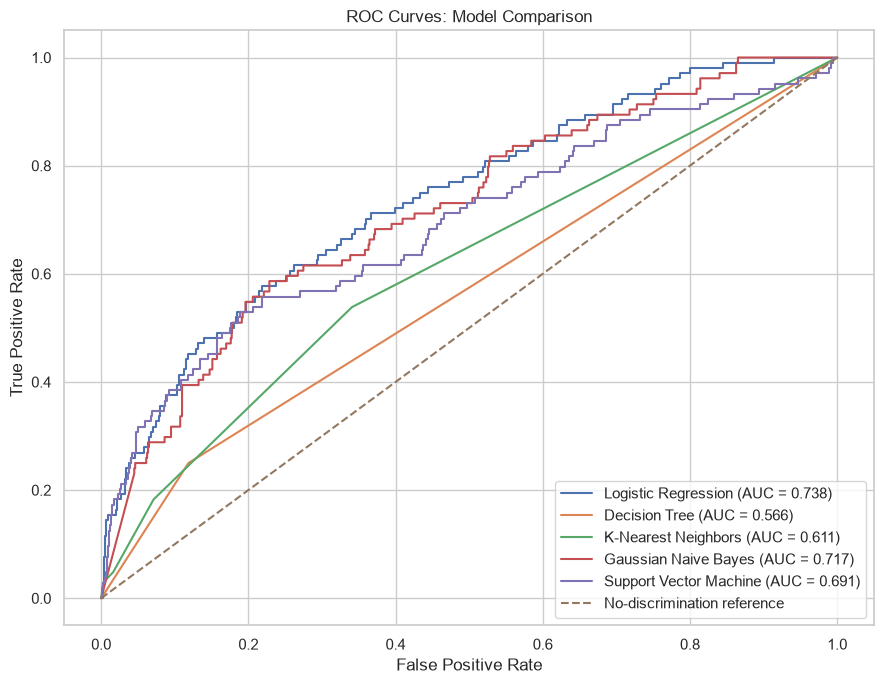

In [8]:
plt.figure(figsize=(9, 7))

for model_name in models:
    fpr, tpr, thresholds = roc_curve(y_test, probabilities[model_name])
    auc_value = roc_auc_score(y_test, probabilities[model_name])

    plt.plot(fpr, tpr, label=f"{model_name} (AUC = {auc_value:.3f})")

plt.plot([0, 1], [0, 1], linestyle="--", label="No-discrimination reference")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves: Model Comparison")
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig(os.path.join(results_dir, "roc_curve_comparison.png"), dpi=150)
plt.show()

## 5.10 Generate model observations

Use the metric table and diagnostic plots to write evidence-based observations. Do not assume that the model with the highest Accuracy is automatically the winner.

Consider:
- Accuracy: overall fraction of correct predictions.
- AUC: ability to rank positive cases above negative cases across thresholds.
- Precision: reliability of positive predictions.
- Recall: fraction of actual subscribers identified.
- F1: harmonic mean of Precision and Recall.
- MCC: balanced correlation measure based on all four confusion-matrix outcomes.

For a marketing campaign, missing likely subscribers (false negatives) may be costly, but contacting customers who will not subscribe (false positives) also has a cost. State the trade-off when selecting the winner.

In [9]:
# Sort models by F1 and AUC as useful comparison views.
display(metrics_df.sort_values("F1", ascending=False).round(4))
display(metrics_df.sort_values("AUC", ascending=False).round(4))

,Accuracy,AUC,Precision,Recall,F1,MCC
ML Model Name,,,,,,
Gaussian Naive Bayes,0.8099,0.7166,0.2763,0.4038,0.3281,0.2274
Logistic Regression,0.8873,0.7376,0.5333,0.1538,0.2388,0.2429
Decision Tree,0.8088,0.5657,0.2149,0.2500,0.2311,0.1231
Support Vector Machine,0.8884,0.6909,0.5600,0.1346,0.2171,0.2352
K-Nearest Neighbors,0.8762,0.6112,0.2778,0.0481,0.0820,0.0727


,Accuracy,AUC,Precision,Recall,F1,MCC
ML Model Name,,,,,,
Logistic Regression,0.8873,0.7376,0.5333,0.1538,0.2388,0.2429
Gaussian Naive Bayes,0.8099,0.7166,0.2763,0.4038,0.3281,0.2274
Support Vector Machine,0.8884,0.6909,0.5600,0.1346,0.2171,0.2352
K-Nearest Neighbors,0.8762,0.6112,0.2778,0.0481,0.0820,0.0727
Decision Tree,0.8088,0.5657,0.2149,0.2500,0.2311,0.1231


## 5.11 Record observations and select a model

Complete the table after reviewing the metrics, confusion matrices, and ROC curves. The notebook does not automatically declare a winner because the appropriate choice depends on the assignment's interpretation and the business trade-off.

In [10]:
observations = pd.DataFrame({
    "ML Model Name": list(models.keys()),
    "Observation about model performance": [
        "Describe Accuracy, AUC, Precision, Recall, F1, MCC and confusion-matrix behaviour.",
        "Describe Accuracy, AUC, Precision, Recall, F1, MCC and confusion-matrix behaviour.",
        "Describe Accuracy, AUC, Precision, Recall, F1, MCC and confusion-matrix behaviour.",
        "Describe Accuracy, AUC, Precision, Recall, F1, MCC and confusion-matrix behaviour.",
        "Describe Accuracy, AUC, Precision, Recall, F1, MCC and confusion-matrix behaviour."
    ]
})

display(observations)

,ML Model Name,Observation about model performance
0,Logistic Regression,"Describe Accuracy, AUC, Precision, Recall, F1,..."
1,Decision Tree,"Describe Accuracy, AUC, Precision, Recall, F1,..."
2,K-Nearest Neighbors,"Describe Accuracy, AUC, Precision, Recall, F1,..."
3,Gaussian Naive Bayes,"Describe Accuracy, AUC, Precision, Recall, F1,..."
4,Support Vector Machine,"Describe Accuracy, AUC, Precision, Recall, F1,..."


## 5.12 Save final evaluation artifacts

The metrics table and ROC comparison plot are saved under `results/`. The confusion matrices are also saved individually in that directory.

These outputs will be used to prepare the README comparison table and the assignment submission PDF.

In [11]:
print("Evaluation files generated:")
for filename in sorted(os.listdir(results_dir)):
    print("-", filename)

Evaluation files generated:
- model_metrics_comparison.csv
- roc_curve_comparison.png
